# GNN-guided coarsening for CVRPTW: a computational audit of the reported results

Author: Bartosz Tomsia

Date: 2026-10-25

The manuscript ["GNN-Guided Graph Coarsening and Adaptive QUBO Penalties for the Capacitated Vehicle Routing Problem with Time Windows on a Quantum Annealer"](https://arxiv.org/abs/2609.04593v2) [1] coarsens CVRPTW instances before solving them as a QUBO and reports that coarsened solutions are feasible more often when a graph neural network (GNN) chooses the merges than when a hand-designed score tuned per Solomon family does. This report asks how much of that difference the learned score explains, and how far the measurements behind it can be taken at face value.

Three coarsening arms are compared on the same instances, sizes and seeds:

* **tuned heuristic** (`heuristic`) - the score $D_{ij}$ of Eq. (1), with settings tuned per family;
* **heuristic-fixed** (`heuristic_fixed`) - the same score with the GNN's settings, P = 0.5 and radiusCoeff = 0.5, which [1] defines as the control that isolates the score;
* **GNN** (`gnn`) - the learned score, with those same settings.

Each solution is measured at three points:

1. **pre-repair** - the raw decoded sample on the coarse problem, as [1] reports it;
2. **on the coarse graph** - after the repair step, before expansion;
3. **after expansion** - every super-node replaced by its two customers and the routes scored on the original instance; this is the coarsened feasibility [1] reports.

We run the released experiment scripts unchanged and collect additional measurements at intermediate stages of the same pipeline. Experiments use simulated annealing on CPU and the published GNN checkpoint (`results/gnn_model_rl.pt`); the model is not retrained. Values from [1] serve only as references for comparison.

The analyses begin with the headline comparison and then examine what its measurements contain: the step that expands coarse routes, the pre-repair metrics, the dependence of the merges on edge order and hash salt, the composition of the test set, and the selection of training labels. Implementation details, every check and the command record are in the appendix.

## Setup

The implementation lives in the modules of `content/`; this cell loads them and stops if one is missing.

In [ ]:
import importlib.util, subprocess, sys
from pathlib import Path

for _pkg in ("pypdf", "jinja2"):
    if importlib.util.find_spec(_pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", _pkg], check=True)

BASE = Path("/content") if Path("/content").is_dir() else Path.cwd()
AUDIT = Path.cwd() / "content" if (Path.cwd() / "content" / "audit_runner.py").is_file() else BASE
INPUT_FILES = ['audit_runner.py', 'audit_probe.py', 'audit_verify.py', 'audit_report.py', 'audit_config.json', 'audit_remarks.json', 'audit_fragments.json', 'requirements-pipeline.txt']
missing = [f for f in INPUT_FILES if not (AUDIT / f).is_file()]
if missing:
    raise FileNotFoundError(f"upload to {AUDIT}: " + ", ".join(missing))
sys.path.insert(0, str(AUDIT))
import audit_report, audit_runner, audit_verify
print(f"inputs: {AUDIT} ({len(INPUT_FILES)} files) | output: {BASE / 'output'} | Python {sys.version.split()[0]}")

inputs: /content (8 files) | output: /content/output | Python 3.13.16


The notebook works in one of two modes. In **generate** mode the experiments run and every observation is written to `output/results.json`; in **reanalyse** mode a saved results file is read and no experiment runs. `RUN_FULL` selects the grid, quick or published; a saved file is accepted only with the grid and inputs it was produced with.

In [ ]:
MODE = "generate"     # "generate": run the experiments and write output/results.json
                        # "reanalyse": read a saved output/results.json; no experiment runs
RUN_FULL = False        # grid: False = quick grid, True = the published grid

assert MODE in ("generate", "reanalyse"), MODE
cfg = audit_runner.load_config(AUDIT, run_full=RUN_FULL)
print(f"mode {MODE}; grid {cfg['mode']}; workers {cfg['workers']}; config sha256 {audit_runner.config_digest(cfg)[:12]}…")
print("grid:", "; ".join(f"N={N} seeds {s}" for N, s in cfg["grid"].items()), "| salts:", cfg["alt_salts"])

mode generate; grid QUICK; workers 2; config sha256 85a0df30e656…
grid: N=10 seeds [0, 1, 2]; N=20 seeds [0, 1, 2]; N=40 seeds [0, 1, 2]; N=80 seeds [0]; N=100 seeds [0] | salts: [1, 2, 3]


## Observations

Generation runs its stages in a fixed order - the data and the unmodified ablation script, the main grid of the three arms, the edge-order and hash-salt variants, and the training-label pool - and saves the results file after each stage; it is marked complete only when every stage is done. Each command and its output go to a log shown in the appendix. In reanalyse mode the stages are skipped.

In [ ]:
run = audit_runner.AuditRun(cfg, base=BASE, audit_dir=AUDIT, verify_only=MODE == "reanalyse")
with audit_report.stage_log(run):
    run.prepare()
    run.sources()
    run.data_and_scripts()
    run.main_grid()
    run.edge_order()
    run.hash_salts()
    run.label_stability()
    run.finish()

stage 'prepare' done in 124 s
stage 'sources' done in 2 s
stage 'data_and_scripts' done in 307 s
stage 'main_grid' done in 1062 s
stage 'edge_order' done in 1051 s
stage 'hash_salts' done in 609 s
stage 'label_stability' done in 407 s
/content/output/results.json (4.9 MB): status complete
89 commands; stage time 59.4 min; 20 artifacts listed
full log of this generation: /content/output/generation_log.txt (appendix)


Verification reads only the saved results file. It refuses a file produced with another configuration or other generation inputs, recomputes every analysis from the stored observations and gives each check a status: **confirmed**, **not confirmed**, or **insufficient data** (for instance when a comparison needs the published grid). Everything below is drawn from this verification.

In [ ]:
v = audit_verify.verify(run.results_path, AUDIT, expected_config=cfg,
                        allow_incomplete=False)   # True: analyses whose stages are missing are reported as not assessed

results.json: complete, QUICK mode, created 2026-10-13T19:00:11+00:00, config 85a0df30e656…
sources: 95 of 95 distinct passages and lines verified (33 from [1], 55 from [2], 7 from [3])
probe reproduces the unmodified script: True; every customer exactly once: True
56 checks: 50 confirmed, 0 not confirmed, 6 insufficient data


## Summary of findings

One sentence per analysis, generated from the verified results that the sections below show in full.

In [ ]:
audit_report.key_findings(v)

**Quick grid (QUICK)** - N = 10: seeds 0, 1, 2; N = 20: seeds 0, 1, 2; N = 40: seeds 0, 1, 2; N = 80: seed 0; N = 100: seed 0; 3 arms on 13 test instances. These results describe the quick grid. They are not a reproduction of the published grid (N = 10-100 with three seeds per size); comparisons with published aggregates are reported as insufficient data. Results file: status *complete*, created 2026-10-13T19:00:11+00:00. 56 checks: 50 confirmed, 0 not confirmed, 6 insufficient data. The instrumented runs reproduce `scripts/run_scorer_ablation.py` on 351 of 351 shared runs (9 fields, 0 mismatches).

* **GNN versus the heuristic baselines.** Over 142 paired runs the GNN has +25 feasible runs relative to the tuned heuristic: +16 from the settings alone (heuristic-fixed) and +9 from the score with the settings held equal.
* **Statistical tests.** The released large-N test (one-sided, seed means, N = 80 and 100 pooled, GNN vs tuned) gives p = 0.0008; per size and base instance, two-sided, GNN vs heuristic-fixed gives no p below 0.05 (smallest 0.2500); with at most 3 differing base instances per size no exact two-sided test can reach p < 0.05. At N = 10 the arms differ only on R112.
* **Feasibility after expansion.** Expansion turns 24 of 373 coarse-feasible runs infeasible (tuned 6, fixed 14, GNN 4). Before expansion the GNN and heuristic-fixed are feasible equally often (132 runs each); the difference between them after expansion (+9 runs) arises in the lifting step.
* **Pre-repair metrics.** Pre-repair counts compare problems of different size (GNN vs heuristic-fixed: 96 of 142 runs) with a counter that ignores the return to the depot; the pre-repair test gives p = 0.623.
* **Merge sensitivity to edge orientation and hash salt.** Reversing the stored edge orientation changes the first-level merges in 135 of 192 coarsenings and the feasibility of 38 runs; the hash salts tried change 4 coarsenings and 0 outcomes.
* **Test data and the C104 instance.** Test instances other than C104 share their customer maps with 6-18 training instances; C104 loads with 99 customers because line 38 of its file is skipped.
* **Candidate-selection stability.** In 7 of 36 cases the label chosen by one evaluation is not the best candidate on average over 5 seeds.

## GNN versus the heuristic baselines

The headline result of [1] compares the GNN with the heuristic tuned for each family:

> "the GNN's coarsened solutions are feasible more often than the per-family-tuned heuristic's: 83.3% vs. 68.9% overall" ([1], p. 11, section 5.4)

The two arms differ in two respects at once, the merge score and the coarsening settings. [1] defines the comparison that changes only the score,

> "To isolate the effect of the score, we compare it with *heuristic-fixed*, which uses the same coarsening settings as the GNN (P=0.5, radiusCoeff=0.5)." ([1], p. 11, section 5.4)

and reports that at large N the fixed settings alone already do better than tuning:

> "At N=80,100, the tuned heuristic falls to 53.8-58.3% feasibility, below the untuned fixed configuration" ([1], p. 13, section 5.4)

Separating the two changes needs all three arms on the same runs. They share the instances, sizes, sampler seeds and solver budget (200 reads × 200 sweeps, adaptive penalties), and every step from the coarsening to the final evaluation; only the score and, for the tuned arm, the settings differ. Feasibility is measured after expansion on the original instance, as in [1]. The runs come from the instrumented pipeline, which reproduces the unmodified `scripts/run_scorer_ablation.py` on every run the two have in common (appendix).

**Feasibility after expansion per arm and size** - *instrumented pipeline (main grid)* (`tables/feasibility_by_arm_and_size.csv`)

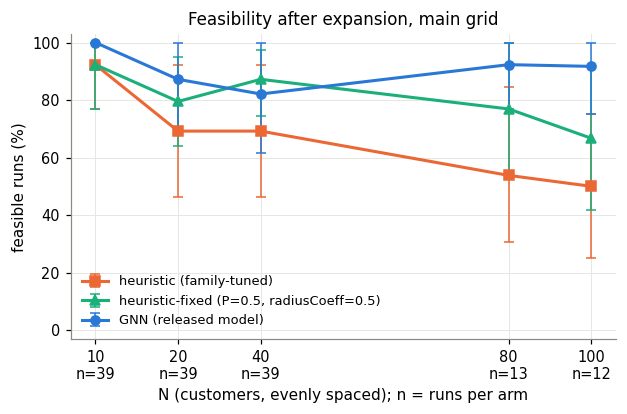

**Paired runs (same instance, size and seed) in which one arm is feasible and the other is not** - *instrumented pipeline (main grid); statistic recomputed by the audit from the runs* (`tables/feasibility_by_arm_and_size.csv`, `tables/paired_arm_comparisons.csv`)

N,runs per arm,tuned %,fixed %,GNN %,GNN vs fixed: better / worse,fixed vs tuned: better / worse,GNN vs tuned: better / worse
10,39,92.300000,92.300000,100.000000,3 / 0,0 / 0,3 / 0
20,39,69.200000,79.500000,87.200000,4 / 1,7 / 3,7 / 0
40,39,69.200000,87.200000,82.100000,3 / 5,10 / 3,8 / 3
80,13,53.800000,76.900000,92.300000,2 / 0,3 / 0,5 / 0
100,12,50.000000,66.700000,91.700000,3 / 0,2 / 0,5 / 0


Over the 142 paired runs, the GNN has +25 feasible runs relative to the tuned heuristic. Giving the tuned heuristic the GNN's settings (heuristic-fixed) changes its count by +16; replacing its score by the GNN with those settings held equal changes it by a further +9. The two parts add up to the total because all arms run on the same instances, sizes and seeds. Against heuristic-fixed, the GNN is feasible where heuristic-fixed is not in 15 runs, and the reverse holds in 6. On this grid the headline comparison therefore combines two changes in the same direction, and the settings alone account for 16 of its 25 net runs. Equal settings do not mean equal problems: the GNN and heuristic-fixed end at different coarse sizes in 44 of 64 instance-size cases.

These counts describe the quick grid (one seed at N = 80 and 100; N = 50 and 60 not run), not the published grid, and the comparisons with the published rates need the full grid. Runs of one instance are not independent, so the counts are descriptive; the tests follow below. The arms are also affected unequally by the expansion step and by the edge orientation (analysed below), which these counts do not separate from the score.

*Checks 11.2, 11.3, 11.9, 11.10, 11.18: 2 confirmed, 3 insufficient data (appendix, table of checks). 11.2, 11.3, 11.18: insufficient data (needs the published grid).*

In [ ]:
audit_report.analysis(v, "baselines")

### Statistical tests

The significance claim for large N rests on `scripts/run_scaling_100.py`. The script runs all three arms but tests one comparison - the GNN against the tuned heuristic - one-sided, on seed means pooled over N = 80 and 100, `scripts/run_scaling_100.py`, [L57](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/scripts/run_scaling_100.py#L57) [2]:

```python
_, p = wilcoxon(x, y, alternative="greater")
```

Section 4 of [1] describes the primary tests differently:

> "take the median across seeds to obtain one value per instance before forming pairs" ([1], p. 8, section 4)

We recompute the script's test from the stored runs and, beside it, the test that Section 4 describes - per size, median over seeds, base instances as the unit, two-sided - for the GNN against both baselines. The 100% feasibility at N = 10 is broken down by instance on the rows saved by the unmodified ablation script; for the same architecture retrained from three seeds, Table 3 of [1] gives

> "87.2 $\pm$ 3.6" ([1], p. 16, section 5.7, Table 3, GraphSAGE, N=10)

In [ ]:
audit_report.analysis(v, "statistics")

**The large-N test as scripts/run_scaling_100.py computes it (seed means, N = 80 and 100 pooled, GNN vs tuned heuristic), recomputed from the stored runs** - *statistic recomputed by the audit from the runs* (`tables/large_n_test.csv`)

data,pairs,better or tied,strictly better,worse,GNN %,tuned %,p one-sided,p two-sided
main grid,25,25,10,0,92.000000,52.000000,0.000800,0.001600


**Per size, median over seeds, base instances as the unit, two-sided Wilcoxon (Section 4 of [1])** - *statistic recomputed by the audit from the runs* (`tables/per_size_two_sided.csv`)

N,base instances,GNN vs fixed: instances better / worse,GNN vs fixed: p two-sided,GNN vs tuned: instances better / worse,GNN vs tuned: p two-sided
10,13,1 / 0,1.000000,1 / 0,1.000000
20,13,2 / 0,0.500000,3 / 0,0.250000
40,13,0 / 1,1.000000,3 / 1,0.625000
80,13,2 / 0,0.500000,5 / 0,0.062500
100,12,3 / 0,0.250000,5 / 0,0.062500


**N = 10: instances not feasible for every seed in every arm (unmodified run_scorer_ablation.py)** - *experiment script, unchanged* (`tables/n10_by_instance.csv`)

condition,heuristic: feasible seeds of 3,heuristic_fixed: feasible seeds of 3,gnn: feasible seeds of 3
instance,,,
R112,0,0,3


Recomputed from the stored runs, the released large-N test gives one-sided p = 0.0008; the same comparison two-sided gives p = 0.0016. It compares the GNN with the tuned heuristic only, on seed means pooled over N = 80 and 100. Tested as Section 4 of [1] describes, per size and base instance and two-sided, the GNN against heuristic-fixed gives no p below 0.05 (smallest 0.2500), and against the tuned heuristic no p below 0.05 (smallest 0.0625). At most 3 base instances differ between the GNN and heuristic-fixed at any size, and an exact two-sided signed-rank test on 3 differences cannot give p below 0.2500; the absence of significance means that this grid cannot resolve the difference at the 5% level, not that there is none. At N = 10 the arms differ on one instance (R112: heuristic 0/3, heuristic_fixed 0/3, gnn 3/3); every other test instance is feasible for every seed in every arm, so the 100% at N = 10 rests on that instance. The retraining mean of Table 3 of [1], 87.2%, lies 1.66 instances below 100% on a test set of 13 instances.

On the quick grid N = 80 and 100 have one seed, so the median over seeds there is a single run, and the published p-values are not compared. The retrained models of Table 3 of [1] are not re-run; 87.2 ± 3.6 is quoted.

*Checks 11.1, 11.4, 11.5, 11.6, 11.7, 11.8, 11.11, 11.12, 11.13, 11.14, 11.15, 11.16, 11.17: 11 confirmed, 2 insufficient data (appendix, table of checks). 11.14, 11.16: insufficient data (needs the published grid).*

## Feasibility after expansion

The feasibility in [1] is measured after each super-node has been expanded back into its two customers. A super-node sits at the midpoint of its pair, with the travel inside the pair added to its service time in `src/coarsening.py` [2]:

[L265](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L265):

```python
s_ij = ni.s + tau_internal + nj.s
```

[L267](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L267):

```python
sid, (ni.x + nj.x) / 2, (ni.y + nj.y) / 2, s_ij, e_prime, l_prime,
```

Travel to and from a super-node is measured from that midpoint, but the expanded route drives to the first customer of the pair and leaves from the second, and it is scored at once, with no repair in between, `src/experiment.py`, [L83](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/experiment.py#L83) [2]:

```python
metrics = calculate_route_metrics(metrics_graph, routes, depot_id, capacity)
```

[1] describes the construction as one that

> "preserves distance consistency after inflation" (p. 4, section 3.1)

If expansion alone can break time windows, the reported feasibility mixes the quality of the coarse solution with an error of the lifting step, possibly unequally across arms. On every run of the main grid we therefore score the same solution twice with the evaluator of the final metric, `calculate_route_metrics`, which includes the return to the depot: on the coarse graph after repair, and on the original instance after expansion. These are added measurements; the pipeline itself is unchanged. A run is *lost at expansion* if it is feasible on the coarse graph and infeasible after expansion.

**Feasibility on the coarse graph (repaired, dashed) and after expansion (solid)** - *audit measurement on the main-grid runs* (`tables/feasibility_by_stage.csv`)

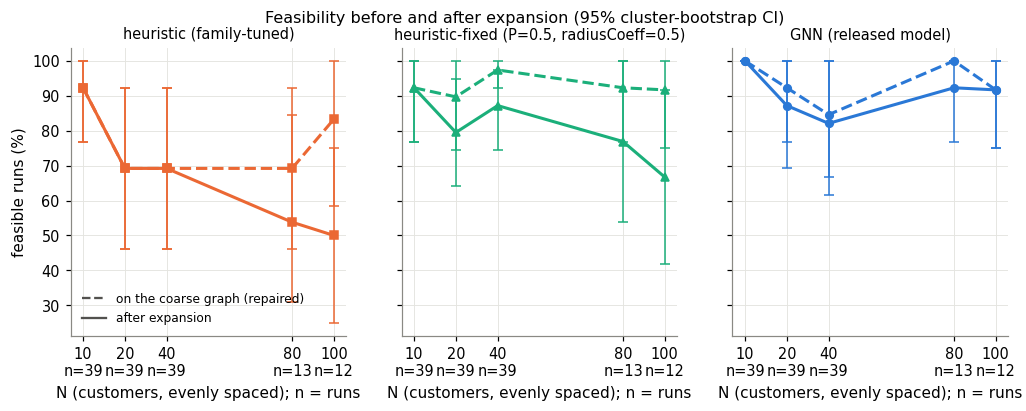

**Runs feasible on the coarse graph that are infeasible after expansion** - *audit measurement on the main-grid runs* (`tables/loss_at_expansion.csv`)

,N = 10: lost / coarse-feasible,N = 20: lost / coarse-feasible,N = 40: lost / coarse-feasible,N = 80: lost / coarse-feasible,N = 100: lost / coarse-feasible,"runs, all sizes","coarse-feasible, all sizes","feasible after expansion, all sizes","lost, all sizes"
arm,,,,,,,,,
heuristic (family-tuned),0 / 36,0 / 27,0 / 27,2 / 9,4 / 10,142,109,103,6
"heuristic-fixed (P=0.5, radiusCoeff=0.5)",0 / 36,4 / 35,5 / 38,2 / 12,3 / 11,142,132,119,14
GNN (released model),0 / 39,2 / 36,1 / 33,1 / 13,0 / 11,142,132,128,4


**Expanded length minus (coarse length + internal legs of the merged pairs)** - *audit measurement on the main-grid runs* (`tables/distance_gap.csv`)

arm,runs,gap_nonzero,median_gap,min_gap,max_gap
heuristic,142,142,-0.160000,-48.620000,45.500000
heuristic_fixed,142,142,-0.310000,-55.170000,61.420000
gnn,142,142,-2.180000,-67.920000,47.780000


Expansion alone turns 24 of 373 coarse-feasible runs infeasible (tuned 6, fixed 14, GNN 4), most at N = 100 (7 of 32). Before expansion the GNN and heuristic-fixed are feasible in 132 and 132 of 142 runs; after expansion in 128 and 119. Of their difference after expansion (+9 runs), +9 - all of it on this grid - arises in the lifting step, not in the coarse solutions. In 426 of 426 runs the expanded length differs from the coarse length plus the internal legs of the merged pairs: distances are consistent only for the leg inside a pair.

Both measurements use the evaluator of the reported feasibility on the same runs. Whether a repair after expansion, or a super-node that keeps the entry and exit of its pair, would remove the loss is not computed; both are changes of method. At N ≥ 80 there are 12-13 runs per arm and size, so the loss rates there are imprecise (Wilson intervals in the appendix).

*Checks 9.1, 9.2, 9.3, 9.4, 9.5, 9.6: 6 confirmed (appendix, table of checks).*

In [ ]:
audit_report.analysis(v, "expansion")

## Pre-repair metrics

[1] compares the arms on pre-repair quantities, read as raw solver and coarsening quality:

> "Under matched settings, its difference in pre-repair violations from a fixed-parameter heuristic is not significant (p=0.62 pooled over N)." ([1], p. 21, section 8)

Such counts are comparable only if both arms are counted on a common problem with the definition of the final metric. The pre-repair report is computed on the raw decoded sample before expansion, that is, on each arm's own coarse problem, `src/experiment.py`, [L76](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/experiment.py#L76) [2]:

```python
pre = sol.report(sol.raw_solution)  # pre-repair SA quality (int space)
```

and its time-window counter walks the customers of a route and stops, without the return to the depot, `src/solvers.py`, [L120](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/solvers.py#L120) [2]:

```python
for idx in range(len(route) - 1):
```

On the same runs of the main grid we compare the coarse problem sizes the arms hand the sampler, score a constructed route that returns late with both the pre-repair counter and the final evaluator, and measure every raw sample three ways: as reported, on the coarse problem including the return, and expanded onto the original customers with the final evaluator. The pre-repair test of [1] is then recomputed with the code of `scripts/run_scorer_ablation.py`, on the reported and on the original-instance measurement.

In [ ]:
audit_report.analysis(v, "pre_repair")

**Runs in which two arms hand the sampler coarse problems of different size** - *instrumented pipeline (main grid)* (`tables/problem_size_by_arm_pair.csv`)

pair of arms,runs,different coarse problem size
gnn vs heuristic_fixed,142,96
gnn vs heuristic,142,123
heuristic vs heuristic_fixed,142,110


**A constructed route that returns to the depot late, scored by the pre-repair counter and the final evaluator** - *data loader and functions applied to the data* (`tables/depot_return_example.csv`)

solver_counter_violations,solver_report_feasible,final_evaluator_violations
0,True,1


**The pre-repair test of [1] (code of run_scorer_ablation.py) on both measurements** - *statistic recomputed by the audit from the runs* (`tables/pre_repair_test.csv`)

measurement,cells,one-sided p (script),two-sided p,printed by the script
coarse problem (authors),39,0.623200,0.753700,0.623000
original instance,39,0.651000,0.697900,nan


On the same run, the GNN and heuristic-fixed hand the sampler coarse problems of different size in 96 of 142 runs, so their pre-repair counts are counts on different problems. The pre-repair counter stops at the last customer: on the constructed route it counts 0 violations where the final evaluator counts 1, and 217 raw routes of the main grid return to the depot late. Measured on the original instance with the final evaluator, pre-repair feasibility differs from the reported measurement in 2 of 426 runs. The pre-repair test of [1] reproduces (one-sided p = 0.623; the script prints 0.623); on the original-instance measurement it gives p = 0.651. A large p here does not show equal pre-repair quality: the test compares counts on problems of different size.

The depot-return omission changes the pre-repair verdict in 2 of 426 runs of this grid (0.5%); whether it matters for the hardware comparison of Section 6 of [1], which uses the same counter, is not tested.

*Checks 10.1, 10.2, 10.3, 10.4: 4 confirmed (appendix, table of checks).*

## Merge sensitivity to edge orientation and hash salt

Every comparison between arms assumes that a difference in outcome comes from the merge score, and [1] states that the compared conditions share everything else:

> "All compared conditions receive the same solver budget, including the backend, number of reads, sweeps, and seed" ([1], p. 8, section 4)

Two properties of the coarsening could break that assumption. The first is processing order. Candidate pairs are sorted on the score alone, so pairs with equal scores keep the order of the edge list; after each merge, new edges are added while iterating over a Python set of string identifiers, whose order depends on the interpreter's hash salt; and the seed function sets that salt from inside the running interpreter, where it no longer affects string hashing. In `src/coarsening.py` [2]:

[L225](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L225):

```python
sorted_edges = sorted(G.edges, key=lambda e: e.D_ij)
```

[L210](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L210):

```python
nbrs = (g.get_neighbors(ni.id) | g.get_neighbors(nj.id)) - {
```

and in `src/utils.py`, [L26](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/utils.py#L26) [2]:

```python
os.environ["PYTHONHASHSEED"] = str(seed)
```

The second is orientation. The score of Eq. (1) is directional - it charges the waiting time at $j$ when the vehicle travels from $i$ to $j$ - but it is evaluated with $i$ as the edge's stored first endpoint, and the order in which the pair is merged is chosen only afterwards, by slack, in `src/coarsening.py` [2]:

[L156](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L156):

```python
ni = graph.nodes[edge.u_id]
```

[L245](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/coarsening.py#L245):

```python
pi_order, _ = self._order_by_slack(ni, nj)
```

Both are tested on the cases of the main grid. Re-running the coarsening in processes started with other hash salts changes no code; cases whose coarsening changes are solved again under that salt, and unchanged cases serve as a control. Two control variants change the code on purpose: a deterministic tie-break, which breaks ties by node rank, and a reversed orientation, which creates every edge with its endpoints swapped and is applied to the main grid and to the heuristic settings of the training-label pool. The same constructs are traced to the first version of the predecessor's code [3].

In [ ]:
audit_report.analysis(v, "merge_order")

**Coarsenings of the main grid under other hash salts, a deterministic tie-break and the reversed edge orientation** - *audit measurement on the main-grid runs; pipeline under other hash salts; control variant (intentional change)* (`tables/ties.csv`, `tables/salt_variation.csv`, `tables/canonical_tie_break.csv`, `tables/orientation.csv`, `tables/orientation_counterfactual.csv`, `tables/properties_by_arm.csv`)

arm,coarsenings,with tied scores,"differ across salts 0, 1, 2, 3","differ, deterministic tie-break",merges executed against the scored direction,"first-level merges changed, reversed orientation",runs whose feasibility changes: salt,runs whose feasibility changes: reversed orientation
heuristic (family-tuned),64,58,0 / 64,0 / 64,54.9%,54 / 64,0,7
"heuristic-fixed (P=0.5, radiusCoeff=0.5)",64,57,4 / 64,0 / 64,53.7%,48 / 64,0,15
GNN (released model),64,0,0 / 64,0 / 64,54.3%,33 / 64,0,16


Setting `PYTHONHASHSEED` from inside the running process leaves string hashing unchanged in every fresh process tested, so the seed function does not fix the order in which edges are added after a merge. Tied scores below the admission threshold occur in 115 of 128 heuristic coarsenings and 0 of 64 GNN coarsenings. Under the salts tried, 0 of 64 `heuristic` coarsenings, 4 of 64 `heuristic_fixed` coarsenings and 0 of 64 `gnn` coarsenings change; none of the re-solved runs changes its feasibility outcome, and with a deterministic tie-break no case varies. The stored edge orientation has a larger effect: 54-55% of merges are executed in the direction opposite to the one in which they were scored, and creating every edge in the opposite order changes the first-level merges in 54 of 64 `heuristic`, 48 of 64 `heuristic_fixed` and 33 of 64 `gnn` coarsenings, and 561 of 645 coarsenings of the training-label pool. It changes the feasibility outcome of 7 `heuristic`, 15 `heuristic_fixed` and 16 `gnn` runs; for comparison, the GNN minus heuristic-fixed on the same runs is +9 feasible runs (GNN versus the heuristic baselines). The score-only sort, the set-based reconnection and the scoring orientation are already in the first version of the predecessor's code [3]; the in-process seeding is not.

The reversed orientation is a counterfactual convention: it shows that the stored orientation decides which pairs merge, not which convention is better. Only 4 salts are tried, and the salts of the published runs were not recorded, so salt-driven variation in the published numbers cannot be measured.

*Checks 8.1, 8.2, 8.3, 8.4, 8.5, 8.6, 8.7, 8.8, 8.9, 8.10, 8.11, 8.12: 11 confirmed, 1 insufficient data (appendix, table of checks). 8.5: insufficient data (needs the published grid).*

## Test data and the C104 instance

[1] presents one configuration that works across all Solomon families and evaluates it on held-out instances:

> "family-stratified split of 43 training and 13 held-out test instances" ([1], p. 8, section 4)

> "we retain the first N customers for N=5 through the complete N=100 instance" ([1], p. 8, section 4)

If a held-out instance has the same customers as training instances, the test measures new time windows on familiar customer maps rather than new geometry; if an instance is loaded incompletely, the size series and the number of comparison pairs change. We apply the loader and the split of `src/datasets.py` [2] - every fourth instance of each Solomon series is held out - to all 56 instances and count, for every test instance and size, the training instances whose first N customers have the same coordinates and demands. No solver runs here. We also read the C104 file row by row and compare it with what the loader returns. One row is malformed, `data/solomon/C1/C104.csv`, [L38](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/data/solomon/C1/C104.csv#L38) [2]:

```text
37,5,45,10,0.00    1,110,90
```

and the loader skips any row whose fields do not convert to numbers, `src/datasets.py`, [L218](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/src/datasets.py#L218) [2]:

```python
except (KeyError, ValueError):
```

In [ ]:
audit_report.analysis(v, "test_data")

**Training instances with the same first N customers (coordinates and demands) as each test instance** - *data loader and functions applied to the data* (`tables/shared_customer_maps.csv`)

N,10,20,40,50,60,80,100
test instance,,,,,,,
C104,7.000000,7.000000,0.000000,0.000000,0.000000,0.000000,nan
C108,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
C204,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
C208,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
R104,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
R108,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
R112,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
R204,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
R208,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000


**Data rows of C104.csv that do not parse as seven numbers** - *source code or data files at the pinned commit* (`tables/c104_rows_not_parsed.csv`)

file line,fields,content
38,7,"37,5,45,10,0.00 1,110,90"


**Whether the loaded C104 equals the first N customers of its file** - *data loader and functions applied to the data* (`tables/c104_size_series.csv`)

N,loaded C104 = first N customers of the file,used in the experiments
10,True,yes
20,True,yes
40,False,yes
50,False,yes
60,False,yes
80,False,yes
100,None,excluded (fewer than N customers)


Every test instance except C104 has the same customers - positions and demands - as 6-18 training instances at every evaluated size; only the time windows differ. In the R and RC classes the two series also share their coordinates; C1 and C2 do not. C104 is loaded with 99 customers: line 38 of its file has the ready time '0.00    1', the loader skips the row without a warning, and from N = 36 on the loaded instance is no longer the first N customers of the benchmark. At N = 100 it is excluded, which leaves 25 instance-size pairs at N = 80, 100 and 90 over the seven published sizes.

How much the altered C104 changes any reported number is not measured. The split shows what the test set contains; it cannot show how the model does on unseen customer maps, since none is evaluated.

*Checks 7.1, 7.2, 7.3, 7.4, 7.5, 7.6, 7.7, 7.8, 7.9, 7.10, 7.11, 7.12: 12 confirmed (appendix, table of checks).*

## Candidate-selection stability

The GNN is trained by expert iteration: for each training instance a pool of candidate coarsenings is solved and the best becomes the label. [1] reads the outcome as self-improvement:

> "allowing the policy to improve beyond imitation of the heuristic pool" ([1], p. 8, section 3.5)

`scripts/gen_labels_rl.py` builds one solver configuration with one seed for all candidates, evaluates each candidate once and keeps the first with the highest reward - a reward dominated by two binary feasibility indicators of that single run. In `scripts/gen_labels_rl.py` [2]:

[L119](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/scripts/gen_labels_rl.py#L119):

```python
cfg = SolverConfig("sa", args.num_reads, args.num_sweeps, seed=args.seed)
```

[L51](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/blob/a82c9e30762dc586f537219ac03cc895d12a2c73/scripts/gen_labels_rl.py#L51):

```python
r = 2.0 * float(m["is_feasible"]) + 1.0 * float(m["pre_feasible"])
```

We rebuild the pool as the script does - five heuristic settings and five GNN rollouts, from the same random stream - for a set of training instances, and solve every candidate with several sampler seeds instead of one. Seed 0 is the script's own evaluation; the label it selects is compared with the candidate that is best on average over the seeds. One input is substituted: the script draws its GNN rollouts from `results/gnn_model_multiN.pt`, which is not published, and we use `results/gnn_model_rl.pt`.

In [ ]:
audit_report.analysis(v, "labels")

**The rebuilt candidate pool** - *label-generation functions, several seeds* (`tables/label_runs.csv`)

"cases (instance, N)",candidates per case,seeds,evaluations
36,10,5,1800


**Selection under one evaluation and under the average over seeds** - *label-generation functions, several seeds* (`tables/label_selection.csv`)

"cases (instance, N)",label not best on average,winner varies across seeds,label's reward at seed 0 minus its mean at the other seeds,reward variance explained by the feasibility terms
36,"7/36 (19%, Wilson CI95 10-35%)",22 / 36,mean 0.083 (bootstrap CI95 0.007 to 0.172),97%


,chosen by one evaluation (seed 0),best on average over 5 seeds
type of the candidate,,
GNN rollout,14,14
heuristic setting,22,22


In 7 of 36 instance-size cases (19%) the candidate one evaluation selects is not among those with the highest mean reward over 5 seeds, and the winning candidate changes between seeds in 22 cases. The selected label scores 0.083 higher at its selection seed than on average at the other seeds (95% CI 0.007 to 0.172), the pattern expected when the maximum of single noisy evaluations is kept. Two binary feasibility indicators explain 97% of the reward's variance, so one draw can decide between candidates of similar quality.

The GNN rollouts use the published checkpoint `gnn_model_rl.pt` in place of the unpublished `gnn_model_multiN.pt` of the script, so these runs measure the selection procedure, not the published labels, and the oracle-win rates quoted in [1] are not recomputed. The quick grid uses 12 training instances and 5 seeds; the full mode uses all training instances and more seeds.

*Checks 12.1, 12.2, 12.3, 12.4: 4 confirmed (appendix, table of checks).*

## Implications for the manuscript

Each statement is drawn only where the checks it rests on are confirmed in this run; otherwise the list says which check is missing.

In [ ]:
audit_report.implications(v)

* **GNN versus the heuristic baselines.** The headline compares the GNN with a baseline that differs in its settings as well as its score; on its own it does not show a benefit of the learned score. The comparison with heuristic-fixed should be reported per size, with the coarse problem sizes beside it.
* **GNN versus the heuristic baselines.** The tuning-free result should be credited to the fixed settings unless the learned score is shown to add to it.
* **Statistical tests.** Every p-value should state the test, its sidedness and its unit (run, seed mean or base instance; pooled or per size).
* **Statistical tests.** The 100% at N = 10 should name the instance it rests on and be reported with the retraining mean of Table 3.
* **Feasibility after expansion.** Reported feasibility combines the coarse solution with the error of the lifting step; the loss at expansion should be reported per arm and size, and any repair after expansion introduced as a named change of method.
* **Feasibility after expansion.** The statement on distance consistency should be limited to the leg inside a merged pair.
* **Pre-repair metrics.** Pre-repair numbers are coarse-space quantities with a counter that ignores the return to the depot; they should be labelled as such or measured on the original instance with the definition of the final metric. The p = 0.62 comparison is then a comparison of counts on different problems, not evidence about the learned score.
* **Merge sensitivity to edge orientation and hash salt.** Algorithm 1 should state which endpoint is i, that the merge order is chosen after scoring, and how ties are broken; the seeding should fix the hash salt before the interpreter starts, and the comparisons should be re-run with deterministic coarsening.
* **Test data and the C104 instance.** The family claim should be worded as evaluation on new time windows over customer maps seen in training.
* **Test data and the C104 instance.** The C104 row should be restored, the loader should fail on rows it cannot parse, and the C104 results and the pair counts that depend on it should be recomputed.
* **Candidate-selection stability.** The self-improvement statements should be qualified: the oracle-win rate counts which candidate won one draw. Labels averaged over several seeds would separate a better merge from a lucky sample.

## Implementation and reproducibility

The computation runs in separate steps: generation writes every observation to the results file, which is saved after each stage; verification reads only that file and recomputes every analysis; the report above presents the verified values. The modules in `content/` hold the implementation, and `README.md` documents installation, modes, the results file and the verification rules.

### Execution paths

For each generation stage: the functions of [2] it calls, in order, what is set up or measured around them, and what a control variant changes or substitutes.

**Data facts** - `run.data_and_scripts()` (released functions, no solving) runs `audit_probe.data_facts`.

| # | step | role |
|---|---|---|
| 1 | `src.datasets.list_solomon`, `train_test_split_instances` and `load_solomon` on all 56 instances | function of [2], called |
| 2 | first N customers (`.truncate(N)`) of each test instance compared with every training instance | added measurement |
| 3 | `SpatioTemporalGraphCoarsener.merge_score` with α = 0, β = 1 on every ordered customer pair of the test instances (the β term of Eq. (1)) | function of [2], called |
| 4 | a constructed one-customer route that returns late, scored by `VRPSolution._count_route_tw_violations`, `VRPSolution.report` and `calculate_route_metrics` | function of [2], called |

Counterpart in an unmodified script: not applicable; these are properties of the data and of the functions (test data, merge order, pre-repair metrics).

**Unmodified experiment scripts** - `run.data_and_scripts()` (experiment script, unchanged) runs `scripts/run_scorer_ablation.py` (and `scripts/run_scaling_100.py` on the full grid) from the repository root.

| # | step | role |
|---|---|---|
| 1 | `src.refcache.build_cache` (OR-Tools references) → `src.runner_parallel.build_jobs` (13 test instances, N = 10, 20, 40, seeds 0-2, three arms, adaptive penalties, 200 reads × 200 sweeps, checkpoint `results/gnn_model_rl.pt`) → `src.runner_parallel.run_grid` | experiment script, unchanged |
| 2 | `run_grid` calls `run_one_job` for each job in a process pool; rows go to `results/scorer_ablation.csv`; means and a Wilcoxon test are printed | inside that function |
| 3 | no tracked file of the repository may change | set-up |

Counterpart in an unmodified script: this output is the reference for the instrumented runs (comparison below).

**Main grid** - `run.main_grid()` (instrumented pipeline) runs `audit_probe.staged_job` once per test instance × N × seed × arm; it follows `src.runner_parallel.run_one_job` step by step (seed, truncation, coarsener settings, `solve_on_graph` call, metrics) without calling it.

| # | step | role |
|---|---|---|
| 1 | `src.utils.set_global_seed(seed)` | function of [2], called |
| 2 | `src.datasets.load_solomon(instance).truncate(N)` | function of [2], called |
| 3 | `src.solvers.SolverConfig('sa', 200, 200, seed=seed)` | function of [2], called |
| 4 | `src.coarsening.graph_from_instance(inst)` | function of [2], called |
| 5 | coarsener: `SpatioTemporalGraphCoarsener` with the family settings (`heuristic`) or α = β = 1, P = 0.5, radiusCoeff = 0.5 (`heuristic_fixed`); `GNNCoarsener` with P = 0.5, radiusCoeff = 0.5 and the checkpoint (`gnn`). Each is subclassed with `audit_probe.LogMixin`, whose methods call the original ones and then only record | set-up |
| 6 | `coarsener.coarsen()`; `audit_probe.coarsen_summary` then summarises the merges (partition, ties, merges executed against their scored direction) | function of [2], called |
| 7 | `src.experiment.solve_on_graph(coarse, depot, capacity, 'FQS', cfg, penalty_mode='adaptive', coarsener=coarsener)` | function of [2], called |
| 8 | `vrp_problem_from_graph` → `adaptive_penalties` → `solve_vrp` | inside that function |
| 9 | `solve_vrp`: `get_qubo` → `solve_qubo` (SimulatedAnnealingSampler, reads, sweeps, seed) → `VRPSolution`: decoded `raw_solution`, then `_repair_solution` and `_repair_time_windows` | inside that function |
| 10 | `report(raw_solution)` gives the pre-repair metrics; `inflate_route` expands the repaired routes; `calculate_route_metrics` scores them on the original instance | inside that function |
| 11 | raw routes: `audit_probe.route_schedule` with and without the return to the depot, alongside `VRPSolution._count_route_tw_violations` | added measurement |
| 12 | raw routes expanded with `inflate_route` and scored with `calculate_route_metrics` on the original instance; `audit_probe.coverage` checks that every customer appears once | added measurement |
| 13 | repaired routes scored on the coarse graph (`calculate_route_metrics`, `VRPSolution.check()`); coverage and distance of the expanded routes | added measurement |

Counterpart in an unmodified script: compared field by field with `run_scorer_ablation.py` on every run both contain (comparison below).

**Reversed edge orientation** - `run.edge_order()` (control variant) runs `audit_probe.staged_job` with `orient='flipped'` (steps of the main grid), and `audit_probe.signature_job` (coarsening only) for the label pool.

| # | step | role |
|---|---|---|
| 1 | edges from `graph_from_instance` get `u_id` and `v_id` swapped before coarsening | control: intentional change |
| 2 | `audit_probe.FlipMixin._reconnect` replaces `_reconnect`: edges added after a merge are created as (neighbour, super-node) instead of (super-node, neighbour). D_ij is directional, with i = the edge's first endpoint, and `build_features` builds the GNN's candidate-edge features in stored order, so the change can alter which pairs score lowest in every arm | control: intentional change |
| 3 | label pool: the five heuristic settings `SWEEP` of `scripts/gen_labels_rl.py`, applied with `SpatioTemporalGraphCoarsener` to every training instance at N = 10, 15, 20 in both orientations; coarsening only | set-up |

Counterpart in an unmodified script: none; no released script runs this variant.

**Hash salts and the deterministic tie-break** - `run.hash_salts()` (pipeline under other hash salts, and a control variant) runs a hash probe, then `signature_job` and `staged_job` under each `PYTHONHASHSEED`, and `signature_job` with `tie='canonical'`.

| # | step | role |
|---|---|---|
| 1 | `hash('SN_12_7')` before and after `src.utils.set_global_seed(0)` in fresh processes | function of [2], called |
| 2 | coarsening of every main-grid case recomputed under each salt; no code change | set-up |
| 3 | cases whose coarsening differs from salt 0 solved again under that salt for every seed; unchanged cases solved as a control | set-up |
| 4 | `tie='canonical'`: `audit_probe.CanonicalMixin` sorts the edge list by node rank before each level and reconnects neighbours in rank order, so ties are broken by rank instead of by the salt | control: intentional change |

Counterpart in an unmodified script: the salt runs use the code of the main grid unchanged, and the unchanged cases check that an identical coarsening gives an identical outcome; the canonical tie-break has no counterpart in the released code.

**Training-label pool under several seeds** - `run.label_stability()` (label-generation functions, re-evaluated) runs `audit_probe.label_plan`, then `audit_probe.label_case` per training instance × N.

| # | step | role |
|---|---|---|
| 1 | `label_plan` reproduces the random stream of `gen_labels_rl.main()`: `np.random.default_rng(0)`, consumed in the order N × training instance, four sub-seeds each | set-up |
| 2 | `src.baselines.solve_cvrptw_ortools(inst, time_limit_s=2.0)` for the reference cost | function of [2], called |
| 3 | checkpoint `results/gnn_model_rl.pt` instead of the script default `results/gnn_model_multiN.pt`, which is not published | substituted input |
| 4 | candidates as in `gen_labels_rl.build_pool`: the five `SWEEP` heuristics, a deterministic `GNNCoarsener` (explore = 0) and four stochastic ones (explore = 0.35, the sub-seeds), rebuilt for each SA seed | set-up |
| 5 | `gen_labels_rl.eval_rollout(inst, coarsener, SolverConfig('sa', 200, 200, seed))` and `gen_labels_rl.reward(metrics, ref_cost)` | function of [2], called |
| 6 | `eval_rollout`: `coarsen(record_levels=True)` → `solve_on_graph(..., penalty_mode='adaptive')` | inside that function |
| 7 | every candidate under every seed in `label_seeds`; seed 0 is the script's own evaluation, and its choice (first maximum of the reward) is applied at verification | added measurement |

Counterpart in an unmodified script: none; the script cannot run without `gnn_model_multiN.pt`.

### Instrumented runs and the unmodified script

Every run that the main grid shares with `scripts/run_scorer_ablation.py` is compared field by field.

In [ ]:
audit_report.integrity(v)

351 of the 351 runs of `scripts/run_scorer_ablation.py` also appear in the main grid (N = 10, 20, 40; seeds 0, 1, 2; all three arms; PYTHONHASHSEED 0 in the probe, 0 for the script). On these runs 9 output fields agree within 1e-09: **0 mismatches**.

field,runs compared,tolerance,mismatches
is_feasible,351,|probe − script| ≤ 1e-09,0
pre_feasible,351,|probe − script| ≤ 1e-09,0
pre_total_viol,351,|probe − script| ≤ 1e-09,0
num_qubo_vars,351,|probe − script| ≤ 1e-09,0
coarsen_ratio,351,|probe − script| ≤ 1e-09,0
total_distance,351,|probe − script| ≤ 1e-09,0
tw_violations,351,|probe − script| ≤ 1e-09,0
cap_violations,351,|probe − script| ≤ 1e-09,0
num_vehicles,351,|probe − script| ≤ 1e-09,0


Not covered by this comparison: the 75 main-grid runs at N = 80, 100, the reversed-orientation variant, the deterministic tie-break, the runs under other hash salts, the label re-evaluation (its script needs the unpublished gnn_model_multiN.pt), the data facts. It does not test the solver, repair or evaluator themselves, which both sides share.

runs,records,base instances,sizes,seeds,arms,paired across arms,every customer exactly once
main grid (salt 0),426,13,"10,20,40,80,100","0,1,2","gnn, heuristic, heuristic_fixed",142/142 keys,426/426
opposite orientation (salt 0),426,13,"10,20,40,80,100","0,1,2","gnn, heuristic, heuristic_fixed",142/142 keys,426/426
re-solved under other salts,6,2,"80,100",0,heuristic_fixed,4/4 keys,6/6
salt control sample,12,2,"10,20,40",0,"gnn, heuristic, heuristic_fixed",4/4 keys,12/12


every solution covers each customer exactly once: True
cited passages and lines found at the pinned sources: 95 of 95


### Source of the central functions

`run_one_job` of [2] and the probe's `staged_job`, as `inspect` reads them in the pipeline environment that ran the experiments (available where that environment exists).

In [ ]:
run.show_source("src.runner_parallel.run_one_job", "audit_probe.staged_job")

### Checks

Every check, grouped by analysis: the statement it tests, the measurement, the computed value, its status and kind, and the table that holds its evidence. Check numbers are stable identifiers.

In [ ]:
audit_report.checks(v)

status,confirmed,not confirmed,insufficient data
kind of finding,,,
limitation of the experiment,4,0,0
property or defect of the code or data,26,0,2
reported result recomputed,6,0,3
what the evidence establishes about a claim,14,0,1


**GNN versus the heuristic baselines**

check,statement tested,measurement,computed,status,kind,evidence,origin of the data
11.2,"83.3% vs. 68.9% overall (p. 11, section 5.4)","overall feasibility, GNN vs tuned heuristic (all published sizes)","GNN 90.1% [79.0, 98.6]; tuned 72.5% [52.8, 90.8]",insufficient data,reproduction,tables/feasibility_overall.csv,instrumented pipeline (main grid)
11.3,"tuned 53.8-58.3%, below the untuned fixed configuration (p. 13, section 5.4)","N = 80, 100: tuned heuristic, and heuristic-fixed above it","N=80: tuned 53.8%, fixed 76.9%; N=100: tuned 50.0%, fixed 66.7%",insufficient data,reproduction,tables/feasibility_by_arm_and_size.csv,instrumented pipeline (main grid)
11.9,equal settings do not guarantee equal problem sizes,GNN and heuristic-fixed end at different coarse sizes on the same case,44/64 cases,confirmed,evidence,tables/problem_sizes.csv,instrumented pipeline (main grid)
11.10,a level ends early when no admissible pair is found,coarsenings that stop above the target P·n₀,heuristic: 5/64; heuristic_fixed: 9/64; gnn: 2/64,confirmed,implementation,tables/stopped_above_target.csv,audit measurement on the main-grid runs
11.18,the code properties act on every arm regardless of the scorer,each code property changes feasibility outcomes in every arm,zero for: hash salt / heuristic; hash salt / heuristic_fixed; hash salt / gnn,insufficient data,implementation,tables/properties_by_arm.csv,control variant (intentional change)


**Statistical tests**

check,statement tested,measurement,computed,status,kind,evidence,origin of the data
11.1,"all three arms run; only GNN vs the tuned heuristic tested, one-sided","run_scaling_100.py: arms run, arms tested, sidedness","runs ['heuristic', 'heuristic_fixed', 'gnn']; tests ['gnn, heuristic']; alternative ['greater']",confirmed,evidence,tables/scaling_script_tests.csv,source code or data files at the pinned commit
11.4,"the margin at N = 10 rests on R112 alone: heuristic arms 0/3, GNN 3/3","N = 10: instances below 100% in any arm (unmodified run_scorer_ablation.py, salt 0)","R112: heuristic 0/3, heuristic_fixed 0/3, gnn 3/3",confirmed,evidence,tables/n10_by_instance.csv,"experiment script, unchanged"
11.5,"100% at N = 10; 80% on R-type for the tuned heuristic (p. 11, section 5.3)","N = 10: GNN overall and tuned heuristic on R-type (unmodified script, salt 0)",GNN 100.0%; tuned heuristic on R 80.0%,confirmed,reproduction,tables/n10_by_type.csv,"experiment script, unchanged"
11.6,"13 instances, 5 R-type: 80% on R is four of five, and one instance moves a rate by 7.7 points","test instances, and R-type among them","13 test, 5 R-type; one instance = 7.7 points",confirmed,scope,tables/split_by_series.csv,data loader and functions applied to the data
11.7,one to two instances out of 13,"distance between 100% and the retraining mean 87.2%, in instances of the test set",1.66 instances,confirmed,evidence,-,arithmetic on a value quoted from [1]
11.8,every run is saved; only means are printed,what run_scorer_ablation.py saves and prints,351 rows saved (expected 351); instances printed: none,confirmed,evidence,-,"experiment script, unchanged"
11.11,mean over seeds where Section 4 states a median; N = 80 and 100 pooled into one test; one-sided,"run_scaling_100.py: seed aggregation, pooling of sizes, sidedness","aggregation ['mean'] at L[53]; one test over the jobs of `for N in [80, 100]:`; alternative greater",confirmed,evidence,tables/scaling_script_tests.csv,source code or data files at the pinned commit
11.12,one-sided as well,the other scaling and ablation tests,scripts/run_scaling_large.py:L97 greater; scripts/run_scorer_ablation.py:L67 greater,confirmed,evidence,tables/wilcoxon_calls.csv,source code or data files at the pinned commit
11.13,13 at N = 80 and 12 at N = 100,pairs available at N = 80 and N = 100,13 + 12 = 25,confirmed,reproduction,-,data loader and functions applied to the data
11.14,"better or tied on all 25 available pairs (p. 13, section 5.4)","N = 80, 100 pairs where the GNN is better or tied (script computation)",25/25,insufficient data,reproduction,tables/large_n_test.csv,statistic recomputed by the audit from the runs


...

check,statement tested,measurement,computed,status,kind,evidence,origin of the data
8.1,the salt set after start-up has no effect,set_global_seed changes string hashing in the running process,hash unchanged by the call in 5/5 processes; salt-0 processes agree: True; other salts differ: True,confirmed,implementation,tables/hash_probe.csv,audit measurement on the main-grid runs
8.2,"the coarsening is a function of instance, settings and salt",coarsening identical across SA seeds (main grid),192/192 cases,confirmed,reproduction,-,instrumented pipeline (main grid)
8.3,ties occur,integer coordinates; coarsenings with tied scores below the admission threshold,integer: True; heuristic: 58/64; heuristic_fixed: 57/64; gnn: 0/64,confirmed,implementation,tables/ties.csv,audit measurement on the main-grid runs
8.4,identical inputs and seeds do not give identical coarsenings,"cases whose coarsening differs across salts [0, 1, 2, 3]",heuristic: 0/64; heuristic_fixed: 4/64; gnn: 0/64,confirmed,implementation,tables/salt_variation.csv,pipeline under other hash salts
8.5,a reported comparison can change without any change of method,runs and arm-size rates whose feasibility changes with the salt,0 runs; 0 rates move (largest 0.0 pp),insufficient data,implementation,tables/feasibility_by_salt.csv,pipeline under other hash salts
8.6,a total sort key and sorted neighbour iteration remove the dependence on the salt,"cases with more than one coarsening across salts [0, 1, 2, 3], deterministic tie-break",0/192,confirmed,implementation,tables/canonical_tie_break.csv,control variant (intentional change)
8.7,the score is evaluated with i = the edge's stored first endpoint,edge endpoint rule,0 violations in 192 coarsenings,confirmed,implementation,tables/orientation.csv,audit measurement on the main-grid runs
8.8,a pair can be ranked by a direction in which it is not merged,merges executed opposite to their scored direction,heuristic: 1043/1900 (54.9%); heuristic_fixed: 1032/1922 (53.7%); gnn: 1027/1892 (54.3%),confirmed,implementation,tables/orientation.csv,audit measurement on the main-grid runs
8.9,"the β term charges waiting (earliness), never lateness","β term positive while the arrival is after the window closes (all ordered customer pairs, test instances)",0 of 13697 pairs with a positive term,confirmed,implementation,tables/beta_term.csv,data loader and functions applied to the data
8.10,"which pairs are admitted depends on the order of edge creation, in every arm",first-level admitted merges change when edges are created in the opposite order,heuristic: 54/64; heuristic_fixed: 48/64; gnn: 33/64,confirmed,implementation,tables/orientation_counterfactual.csv,control variant (intentional change)


**Test data and the C104 instance**

check,statement tested,measurement,computed,status,kind,evidence,origin of the data
7.1,family-stratified split of 43 training and 13 held-out test instances,every fourth instance of each series is held out,43 training / 13 test; the rule reproduces the split: True,confirmed,reproduction,tables/split_by_series.csv,data loader and functions applied to the data
7.2,a test instance has the same customers as training instances; only time windows are new,test instances other than C104 share their customers with training instances at every size,84/84 instance-size cells; time windows differ in all of them: True,confirmed,scope,tables/shared_customer_maps.csv,data loader and functions applied to the data
7.3,C104 is the exception from 36 customers on,sizes at which C104 shares its customers with training instances,"N = 10, 20 of [10, 20, 40, 50, 60, 80]",confirmed,implementation,tables/shared_customer_maps.csv,data loader and functions applied to the data
7.4,only the ready time and due date differ,customer 2 of R101 and R104,"same position, demand, service time: True; ready time and due date differ: True",confirmed,scope,tables/customer_R101_R104.csv,data loader and functions applied to the data
7.5,R and RC: shared; C1 and C2: not shared,"series 1 and 2 share coordinates, by class",C: False; R: True; RC: True,confirmed,scope,tables/series_pairs.csv,data loader and functions applied to the data
7.6,row 38 malformed; its ready-time field is not a number,data rows of C104.csv that do not parse as numbers,line 38: ready time '0.00 1',confirmed,implementation,tables/c104_rows_not_parsed.csv,source code or data files at the pinned commit
7.7,"C104 loads with 99 customers, the others with 100",customers the loader returns,C104: 99; the other 55 instances: [100],confirmed,implementation,tables/c104_size_series.csv,data loader and functions applied to the data
7.8,the 36th customer,position of the skipped row among the customers,customer 36 (CUST NO. 37),confirmed,implementation,tables/c104_rows_not_parsed.csv,source code or data files at the pinned commit
7.9,"every N ≥ 36 (evaluated: 40, 50, 60, 80); excluded at 100",smallest N at which the loaded C104 differs from the file's first N customers,"N = 36; evaluated sizes affected: [40, 50, 60, 80]; N = 100 excluded",confirmed,implementation,tables/c104_size_series.csv,data loader and functions applied to the data
7.10,25 rather than 26; 90 rather than 91,"instance-size pairs at N = 80, 100 and over the seven sizes",25 and 90,confirmed,implementation,tables/c104_size_series.csv,data loader and functions applied to the data


**Candidate-selection stability**

check,statement tested,measurement,computed,status,kind,evidence,origin of the data
12.1,each candidate solved once with the same seed; the best is kept,one solver configuration and seed for all candidates; the best kept by '>',"1 SolverConfig call(s) at L[119], inside a loop: 0; comparison ['Eq', 'Is', 'Gt']",confirmed,implementation,tables/label_script_structure.csv,source code or data files at the pinned commit
12.2,the labels partly record selection noise,cases where the label from one evaluation is not the best candidate on average,"7/36 (19%, Wilson CI95 10-35%)",confirmed,evidence,tables/label_selection.csv,"label-generation functions, several seeds"
12.3,the reward is dominated by binary feasibility indicators,share of reward variance explained by 2·feasible + pre-feasible (squared correlation),0.97,confirmed,implementation,-,"label-generation functions, several seeds"
12.4,the maximum over single evaluations is biased toward a favourable sample,label's reward at seed 0 minus its mean reward at the other seeds,mean 0.083 (bootstrap CI95 0.007 to 0.172),confirmed,evidence,tables/label_selection.csv,"label-generation functions, several seeds"


### Full tables

The verified tables behind each analysis, including those the main text shows only in part.

In [ ]:
audit_report.diagnostics(v)

**GNN versus the heuristic baselines**

**Feasibility after expansion with cluster-bootstrap 95% intervals** - *instrumented pipeline (main grid)* (`tables/feasibility_by_arm_and_size.csv`)

arm,N,runs,instances,is_feasible %,CI95 low,CI95 high
gnn,10,39,13,100.000000,100.000000,100.000000
gnn,20,39,13,87.200000,69.200000,100.000000
gnn,40,39,13,82.100000,61.500000,100.000000
gnn,80,13,13,92.300000,76.900000,100.000000
gnn,100,12,12,91.700000,75.000000,100.000000
heuristic,10,39,13,92.300000,76.900000,100.000000
heuristic,20,39,13,69.200000,46.200000,92.300000
heuristic,40,39,13,69.200000,46.200000,92.300000
heuristic,80,13,13,53.800000,30.800000,84.600000
heuristic,100,12,12,50.000000,25.000000,75.000000


**Feasibility after expansion over all sizes of the grid** - *instrumented pipeline (main grid)* (`tables/feasibility_overall.csv`)

arm,runs,instances,is_feasible %,CI95 low,CI95 high
gnn,142,13,90.100000,79.000000,98.600000
heuristic,142,13,72.500000,52.800000,90.800000
heuristic_fixed,142,13,83.800000,71.300000,95.000000


...

**Candidate-selection stability**

**Structure of the selection in gen_labels_rl.py** - *source code or data files at the pinned commit* (`tables/label_script_structure.csv`)

SolverConfig calls in main,inside a loop,line,selection comparison
1,0,[119],"['Eq', 'Is', 'Gt']"


**The label under one evaluation and under the average over seeds, per case** - *label-generation functions, several seeds* (`tables/label_selection.csv`)

instance,N,label at seed 0,its type,best on average,type of the best,label is best on average,distinct winners over seeds,reward at seed 0 minus mean elsewhere
C101,10,5,gnn,[5],gnn,True,1,0.000000
C101,15,1,heur,[1],heur,True,1,0.002509
C101,20,1,heur,[6],gnn,False,3,0.875919
C102,10,9,gnn,[9],gnn,True,1,0.000000
C102,15,0,heur,[0],heur,True,2,0.055699
C102,20,0,heur,[0],heur,True,3,-0.064399
C201,10,0,heur,"[0, 2, 4, 5, 6, 7, 8, 9]",heur,True,2,0.000000
C201,15,0,heur,"[0, 1, 4]",heur,True,3,0.013101
C201,20,5,gnn,[5],gnn,True,2,-0.007306
C202,10,1,heur,[1],heur,True,1,0.000000


### Review points, sources and commands

In [ ]:
audit_report.appendix(v, bundle_dir=BASE)

**Review points → checks**

point,type,title,sections,checks,confirmed,not confirmed,insufficient data
1,answer,The evidence does not isolate a benefit of the learned merge score,"8, 9, 11","8.1, 8.4, 8.5, 8.8, 8.10, 8.12, 9.2, 9.3, 9.4, 11.1, 11.2, 11.3, 11.4, 11.8, 11.18",11,0,4
2,insight,"The merge score ranks each pair in the orientation its edge was created, not the one in which it is merged",8,"8.7, 8.8, 8.9, 8.10, 8.11, 8.12",6,0,0
3,insight,"Tie-breaking depends on the Python hash salt, so identical inputs and seeds do not give identical coarsenings",8,"8.1, 8.2, 8.3, 8.4, 8.5, 8.12",5,0,1
4,insight,Midpoint super-nodes can make a coarse-feasible route infeasible after expansion,9,"9.1, 9.2, 9.3, 9.4, 9.5, 9.6",6,0,0
5,insight,Pre-repair metrics compare different coarse problems and omit the return to the depot,10,"10.1, 10.2, 10.3, 10.4",4,0,0
6,insight,"The headline advantage is measured against the tuned heuristic, not against the control that isolates the score",11,"11.1, 11.2, 11.3, 11.9, 11.10",3,0,2
7,insight,"The significance claim rests on an undeclared one-sided test over pooled, dependent cells","7, 11","7.7, 7.10, 11.11, 11.12, 11.13, 11.14, 11.15, 11.16, 11.17",7,0,2
8,insight,The 100% headline at N = 10 rests on one released model and very few instances,11,"11.4, 11.5, 11.6, 11.7, 11.8",5,0,0
9,insight,The held-out instances share their customer maps with training; only time windows are new,7,"7.1, 7.2, 7.3, 7.4, 7.5",5,0,0
10,insight,The GNN is trained on the best of single noisy evaluations,12,"12.1, 12.2, 12.3, 12.4",4,0,0


**Source verification** (every passage of [1] and line of [2], [3]; `tables/source_verification.csv`)

,verified,total
source,,
[1],45,45
[2],90,90
[3],11,11


not verified: none


file,commit that added it,is the pinned commit
graph_coarsening.py,0d1056a8a86b35615000571b9f88b73bec00b31d,True
solomon_dataset/C1/C104.csv,0d1056a8a86b35615000571b9f88b73bec00b31d,True


**Commands of the generation**, as recorded in the results file (`tables/commands.csv`)

89 commands, 59.3 min in subprocesses; non-zero exits: 1


,count,sum
PYTHONHASHSEED,,
(unset),67,122.6
0,11,2965.7
1,5,161.5
2,3,155.1
3,3,154.7


results bundle: /content/gnn_audit_output.zip


## Limitations

### Scope of the evidence

This audit evaluates the released code, the published checkpoint `results/gnn_model_rl.pt`, and the results obtainable from them under the configurations tested here. It does not reproduce the original execution environment of [1], the unpublished checkpoints, or the full set of runs behind every reported aggregate. All solving uses simulated annealing on CPU, so nothing here says how the same coarsenings behave on the quantum processor. What a script tests and which sizes it covers are read from its source; sizes passed to a script on a command line are not covered.

With `RUN_FULL = False`, the default and the mode of the reference runs, the results come from the QUICK grid: 13 test instances, three arms, seeds 0-2 for N = 10, 20 and 40, and seed 0 for N = 80 and
100. They are therefore not a reproduction of the published grid. Comparisons with published aggregates are reported as insufficient data unless the published grid (`RUN_FULL = True`) was run.

### What the comparisons can support

The paired comparison with `heuristic_fixed` separates the learned score from the GNN's coarsening settings on the same instances, sizes and sampler seeds. It does not establish that the learned score is optimal, robust across all Solomon instances, or superior under other solver budgets, penalty schemes, coarsening ratios, hardware or QUBO formulations.

The comparison with the family-tuned heuristic differs in both the score and the coarsening settings. It can show that the full GNN configuration produces more feasible runs than that baseline in this grid, but it cannot by itself attribute the difference to the learned score.

### Measurement limitations

Feasibility after expansion is the endpoint used by the manuscript, but it combines the quality of the coarse solution with the effect of expanding super-nodes. A run that is feasible before expansion and infeasible afterwards may reflect either a fragile coarse solution or an error introduced by lifting. The audit measures both stages, but cannot separate these contributions for an individual run without additional counterfactual analysis.

Pre-repair violation counts are measured on each arm's own coarse problem and use a route counter that excludes the return to the depot. They are therefore not directly comparable as measures of solution quality across arms. The audit adds measurements on the original instance, but these are diagnostic measurements rather than a replacement for the manuscript's reported metric.

### Statistical scope

The QUICK grid has few independent base instances, especially at N = 80 and N = 100, where only one seed is used. Runs sharing an instance are dependent, so sign tests on runs are descriptive. Confidence intervals and tests reported here describe uncertainty over base instances within this grid; they do not establish population-level superiority of one arm across Solomon instances.

A non-significant result is not evidence of no effect. With the available number of differing base instances, some exact tests cannot reach conventional significance thresholds even if the observed direction favours one arm.

### Unavailable artefacts

The checkpoint used for training-label generation in the released script, `results/gnn_model_multiN.pt`, is not published. The audit substitutes the published `results/gnn_model_rl.pt`, so its label-stability analysis examines the released checkpoint rather than the exact model that produced the manuscript's label set.

The retrained models behind Table 3 of the manuscript are also unavailable. Their reported values are quoted as references and are not reproduced here.

### Determinism and published runs

The merge-sensitivity analysis measures how the stored edge orientation and the hash salt change the coarsening and the feasibility outcomes in this grid. Because the hash salts of the original published runs were not recorded, exact equality with published run-level results cannot be expected. Comparisons with published values therefore use intervals or explicitly marked insufficient-data statuses rather than claims of exact reproduction.

### AI assistance

Claude Code (Anthropic) was used under the direction and supervision of Bartosz Tomsia. It generated the code of this notebook and its supporting audit modules, proposed the concrete measurements, tables and checks that implement the analyses specified by the author, and drafted the explanatory text and the wording of the interpretations generated from the results; Bartosz Tomsia revised parts of the text by hand. Claude Code also wrote the automated tests in `tests/test_review.py` and ran them to check the code; these automated tests are not an independent validation of the results. Bartosz Tomsia takes responsibility for the review, including its methods, interpretation of results and final conclusions.

## References

[1] Y. K. Rezk, P. Gora, "GNN-Guided Graph Coarsening and Adaptive QUBO Penalties for the Capacitated Vehicle Routing Problem with Time Windows on a Quantum Annealer", arXiv:2609.04593v2, 9 Sep 2026, https://arxiv.org/abs/2609.04593v2

[2] [YoussefKamelKamel1/cvrptw-qubo-coarsening](https://github.com/YoussefKamelKamel1/cvrptw-qubo-coarsening/tree/a82c9e30762dc586f537219ac03cc895d12a2c73)

[3] [mkingmking/graph-coarsening](https://github.com/mkingmking/graph-coarsening/tree/0d1056a8a86b35615000571b9f88b73bec00b31d)